# Solving the Traveling Salesman  Problem using Local Search

Points: 10

## The [Traveling Salesman Problem](https://en.wikipedia.org/wiki/Travelling_salesman_problem)

* __Goal:__ Find the shortest tour visiting each of $n$ cities exactly once and returning back to the starting city. Given are pairwise distances between cities, where $d_{i,j}$ is the distance from city $i$ to city $j$. 

* __State space:__ Each state represents a tour. The cities are numbered and a tour can be expressed as vector  $\pi$ with the order in which the cities are visited (a [permutation](https://en.wikipedia.org/wiki/Permutation)). That is, $\pi(1)$ is the index of the first city to visit, $\pi(2)$ the index of the second, and so on.

* __Objective function:__ Minimize the tour length. The optimization problem is to find the optimal tour $\pi^*$ through the $n$ cities and returning to the starting city:

  > minimize: $\mathrm{tourlength}(\pi) = d_{\pi(n),\pi(1)} + \sum_{i = 1}^{n-1} d_{\pi(i),\pi(i+1)}$
  > 
  > subject to: $\pi \ \text{is a valid permutation vector}$

* __Local moves:__ Exchange two cities in the order.

## Helper functions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import random

np.set_printoptions(precision=2)
pd.set_option('display.precision', 2)

# make the results repeatable
np.random.seed(1234)

In [2]:
def random_tour(n):
    """Create a random tour"""
    
    tour = list(range(n))
    random.shuffle(tour)
    return(tour)

random_tour(10)

[3, 5, 4, 7, 2, 8, 0, 1, 6, 9]

In [3]:
from scipy.spatial.distance import pdist
from scipy.spatial.distance import squareform

def random_tsp(n):
    """
    Create a random (Euclidean) traveling salesman problem. Choose n points randomly in a 1 x 1 unit square and calulates a 
    pairwise Euclidean distance matrix.
    """
    
    pos = pd.DataFrame({
        "x" : np.random.uniform(size = n),
        "y" : np.random.uniform(size = n)
    })
    
    dist = squareform(pdist(pos))
    
    return({"pos": pos, "dist": dist})
    
tsp = random_tsp(10)

print(f"Positions:\n{tsp['pos']}")
print(f"Distance matrix:\n{pd.DataFrame(tsp['dist'])})")

Positions:
      x     y
0  0.19  0.36
1  0.62  0.50
2  0.44  0.68
3  0.79  0.71
4  0.78  0.37
5  0.27  0.56
6  0.28  0.50
7  0.80  0.01
8  0.96  0.77
9  0.88  0.88
Distance matrix:
      0     1     2     3     4     5     6     7     8     9
0  0.00  0.45  0.41  0.69  0.59  0.22  0.17  0.70  0.87  0.86
1  0.45  0.00  0.26  0.27  0.20  0.35  0.35  0.52  0.43  0.46
2  0.41  0.26  0.00  0.35  0.46  0.21  0.24  0.76  0.53  0.48
3  0.69  0.27  0.35  0.00  0.34  0.53  0.55  0.70  0.18  0.19
4  0.59  0.20  0.46  0.34  0.00  0.54  0.52  0.36  0.44  0.52
5  0.22  0.35  0.21  0.53  0.54  0.00  0.06  0.76  0.72  0.68
6  0.17  0.35  0.24  0.55  0.52  0.06  0.00  0.72  0.73  0.71
7  0.70  0.52  0.76  0.70  0.36  0.76  0.72  0.00  0.77  0.87
8  0.87  0.43  0.53  0.18  0.44  0.72  0.73  0.77  0.00  0.14
9  0.86  0.46  0.48  0.19  0.52  0.68  0.71  0.87  0.14  0.00)


In [4]:
def tour_length(tsp, tour):
    """Caclulate the length of a tour, i.e., the objective function."""
    
    # make sure tour is a Python list (not an array or a numpy.array)
    if not isinstance(tour, list): tour = tour.tolist()
    
    tl = 0
    dist = tsp["dist"]
    
    for i in range(len(tour)-1):
        tl += dist[tour[i], tour[i+1]]
    
    tl += dist[tour[-1], tour[0]]
    
    return(tl)
        
tour = random_tour(10)
tour_length(tsp, tour)

np.float64(5.304934400264945)

Tour length: 5.3


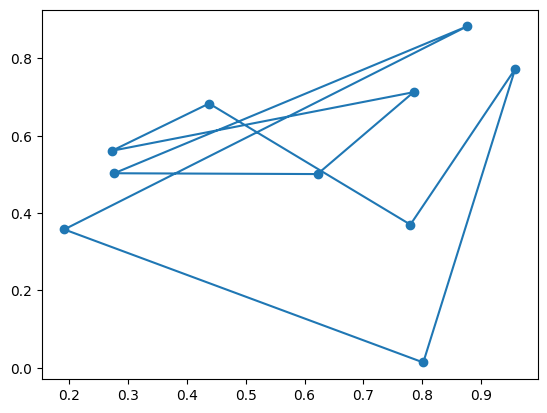

In [5]:
def show_tsp(tsp, tour = None):  
    """display the traveling salesman problem and a tour."""
    
    pos = tsp["pos"]
    
    plt.scatter(pos["x"], pos["y"])
    
    if tour is not None:
        # make sure tour is a Python list (not an array or a numpy.array)
        if not isinstance(tour, list): tour = tour.tolist()
        
        print(f"Tour length: {round(tour_length(tsp, tour), 2)}")
        
        pos_ = pos.reindex(tour)
        pos_ = pd.concat([pos_, pos_.head(1)])
        plt.plot(pos_["x"], pos_["y"])
    
    plt.show()
    
show_tsp(tsp, tour)

### 2-opt for TSP
**Selection and Mechanism**
The 2-opt (2-opt swap) operator is uniformly chosen for all Local Search algorithms in this problem.

It works by selecting two indices $i, j$ ($0 \le i < j < n$) in the tour and reversing the sub-segment of cities from position $i$ to $j$:

$$T = [A, \mathbf{B, C, D}, E] \xrightarrow{i=1, j=3} T' = [A, \mathbf{D, C, B}, E]$$

**Validity Conditions**
- Cycle preservation: Each city appears exactly once; no vertices are added or removed.
- Valid tour structure: Maintains the TSP cycle property, returning to the starting city after visiting every city.
- Duplicate exclusion: Excludes the pair $i = 0, j = n - 1$, as reversing the entire tour merely yields the reverse traversal with the same length (for symmetric TSP).

**Neighborhood Size**
The number of neighbors generated at each iteration is $N = \frac{n(n-1)}{2} - 1$.

In [6]:
def two_opt_swap(tour, i, j):
    """
    Thực hiện phép biến đổi 2-opt: Đảo ngược đoạn tour từ vị trí i đến j.
    """
    new_tour = tour[:i] + tour[i:j+1][::-1] + tour[j+1:]
    return new_tour

def get_all_2opt_neighbors(tour):
    """
    Sinh tất cả các lân cận bằng toán tử 2-opt.
    """
    n = len(tour)
    neighbors = []
    for i in range(n - 1):
        for j in range(i + 1, n):
            # Tránh đảo toàn bộ tour (tương đương tour ban đầu)
            if i == 0 and j == n - 1:
                continue
            neighbors.append((i, j))
    return neighbors

## Steepest-ascend Hill Climbing Search [3 Points]

Calculate the objective function for all local moves (move each queen within its column) and always choose the best among all local moves.

Steepest-Ascent Hill Climbing is a greedy local search algorithm:
- Generate an initial random tour.
- Evaluate all $N = \frac{n(n-1)}{2} - 1$: 2-opt neighbors of the current tour.
- Select the neighbor with the **shortest** total tour length ($T^* = \arg\min_{T' \in N(T)} f(T')$).
- If $f(T^*) < f(T)$, move to the new tour $T^*$. Repeat the process.

The algorithm terminates when **no neighbor is better** than the current tour (a local optimum is reached).

In [7]:
def steepest_ascent_tsp(tsp, initial_tour=None):
    if initial_tour is None:
        current_tour = random_tour(len(tsp["pos"]))
    else:
        current_tour = list(initial_tour)
        
    current_length = tour_length(tsp, current_tour)
    history = [current_length]
    iterations = 0
    evaluations = 0
    
    while True:
        best_neighbor_tour = None
        best_neighbor_length = current_length
        
        # Tái sử dụng hàm sinh danh sách lân cận
        for i, j in get_all_2opt_neighbors(current_tour):
            evaluations += 1
            neighbor = two_opt_swap(current_tour, i, j)
            length = tour_length(tsp, neighbor)
            
            if length < best_neighbor_length:
                best_neighbor_length = length
                best_neighbor_tour = neighbor
                
        if best_neighbor_tour is not None:
            current_tour = best_neighbor_tour
            current_length = best_neighbor_length
            history.append(current_length)
            iterations += 1
        else:
            break
            
    return {
        "solution": current_tour,
        "objective": current_length,
        "history": history,
        "iterations": iterations,
        "evaluations": evaluations
    }

## Steepest-ascend Hill Climbing Search with Random Restarts [1 Point]

Steepest-ascend with random restarts.

Steepest-Ascent with Random Restarts combines the steepest-ascent hill climbing algorithm with multiple random restarts to overcome the limitation of getting stuck in local optima:

- Random Initialization: The algorithm begins by generating an initial random tour.
- Execute Steepest-Ascent: Runs the Steepest-Ascent Hill Climbing algorithm until it converges to a local optimum.
- Store Best Solution: Compares the obtained result with the current best-so-far solution; if better, updates the best solution.
Restart: Generates a new random initial tour and repeats the process until the specified number of restarts (`max_restarts`) is reached.
The algorithm terminates after completing the predefined number of random restarts (`max_restarts`) and returns the solution with the shortest total tour length across all runs.

In [8]:
# Code goes here
def random_restart_tsp(tsp, max_restarts=20):
    best_solution = None
    best_objective = float('inf')
    total_iterations = 0
    total_evaluations = 0
    
    for restart in range(max_restarts):
        res = steepest_ascent_tsp(tsp)
        total_iterations += res["iterations"]
        total_evaluations += res["evaluations"]
        
        if res["objective"] < best_objective:
            best_objective = res["objective"]
            best_solution = res["solution"]
            
    return {
        "solution": best_solution,
        "objective": best_objective,
        "iterations": total_iterations,
        "evaluations": total_evaluations
    }

## Stochastic Hill Climbing [1 Points]

Chooses randomly from among all uphill moves.

## Stochastic Hill Climbing

Stochastic Hill Climbing identifies all better neighbors relative to the current state (uphill moves), then randomly selects one among them to move to.

- Generate an initial random tour and calculate its length.
- Evaluate all $N = \frac{n(n-1)}{2} - 1$ 2-opt neighbors, building a list of tours with a length shorter than the current tour.
   - If the list of better neighbors is not empty: Randomly select one tour from the list and update it as the current tour.
   - If the list is empty: Terminate the algorithm.
- Continue the process until a termination condition is met.

The algorithm terminates when no neighbor is better than the current tour (a local optimum is reached) or when the maximum number of iterations (`max_iterations`) is hit.

In [9]:
def stochastic_hill_climbing_tsp(tsp, max_iterations=1000):
    current_tour = random_tour(len(tsp["pos"]))
    current_length = tour_length(tsp, current_tour)
    history = [current_length]
    evaluations = 0
    iterations = 0
    
    for _ in range(max_iterations):
        better_neighbors = []
        
        # Tái sử dụng danh sách lân cận
        for i, j in get_all_2opt_neighbors(current_tour):
            evaluations += 1
            neighbor = two_opt_swap(current_tour, i, j)
            length = tour_length(tsp, neighbor)
            
            if length < current_length:
                better_neighbors.append((neighbor, length))
                
        if not better_neighbors:
            break  # Mắc kẹt tại cực trị cục bộ
            
        # Chọn ngẫu nhiên 1 lân cận trong danh sách các lân cận tốt hơn
        chosen_neighbor, chosen_length = random.choice(better_neighbors)
        current_tour = chosen_neighbor
        current_length = chosen_length
        history.append(current_length)
        iterations += 1
        
    return {
        "solution": current_tour,
        "objective": current_length,
        "history": history,
        "iterations": iterations,
        "evaluations": evaluations
    }

## First-choice Hill Climbing [1 Point]

First-choice hill climbing is a type of stochastic hill climbing that generates one random local neighbor at a time and accept it if it has a better objective function value than the current state.


Unlike Steepest-Ascent and Stochastic (which must evaluate all $O(n^2)$ neighbors at each step), First-Choice Hill Climbing generates one random neighbor at a time and immediately accepts it if its tour length is shorter than the current tour.

- Initialization: Generate an initial random tour and calculate its length. Set the failed attempt counter `attempts = 0`.
- Generate 1 Random Neighbor: Randomly pick two indices $i, j$ to reverse the sub-segment using the 2-opt operator.
- Check & Update:
   - If the new neighbor tour is shorter than the current tour: Accept the new tour, update the current tour, and reset `attempts = 0`.
   - If the new neighbor tour is longer or equal: Reject it and increment `attempts` by 1.
 Repeat: Continue the process until a termination condition is met.

The algorithm terminates when:
- The consecutive failed attempts to find a better neighbor exceed a threshold (`attempts >= max_attempts`), or the maximum number of iterations (`max_iterations`) is reached.

In [10]:
# Code goes here
def first_choice_hill_climbing_tsp(tsp, max_attempts=500, max_iterations=2000):
    current_tour = random_tour(len(tsp["pos"]))
    current_length = tour_length(tsp, current_tour)
    history = [current_length]
    evaluations = 0
    iterations = 0
    
    n = len(current_tour)
    attempts = 0
    
    while attempts < max_attempts and iterations < max_iterations:
        # Sinh ngẫu nhiên vị trí i, j
        i, j = sorted(random.sample(range(n), 2))
        if i == 0 and j == n - 1:
            continue
            
        evaluations += 1
        neighbor = two_opt_swap(current_tour, i, j)
        length = tour_length(tsp, neighbor)
        
        if length < current_length:
            current_tour = neighbor
            current_length = length
            history.append(current_length)
            iterations += 1
            attempts = 0  # Reset số lần thử thất bại
        else:
            attempts += 1
            
    return {
        "solution": current_tour,
        "objective": current_length,
        "history": history,
        "iterations": iterations,
        "evaluations": evaluations
    }




## Simulated Annealing [2 Points]
Unlike pure Hill Climbing, Simulated Annealing also accepts worse moves with a probability that decreases as temperature $T$ cools, enabling the algorithm to easily "jump" out of local optima and move toward the global optimum.

- Initialization: 
   - Generate an initial random tour and set the initial temperature $T = T_0$.
   - Initialize `best_solution` and `best_objective`.
-  Randomly select a neighbor using the 2-opt operator and calculate the tour length difference: $\Delta = \text{length}_{\text{new}} - \text{length}_{\text{current}}$
   - If $\Delta < 0$ (new tour is **shorter**): **Always accept** the new tour.
   - If $\Delta \ge 0$ (new tour is **longer/worse**): Accept with probability $P = e^{-\frac{\Delta}{T}}$ (generate a random number $r \in [0, 1]$; if $r < P$, accept).
- Update the temperature according to a cooling schedule (e.g., exponential cooling: $T = T \times \alpha$ with $\alpha \approx 0.995$).
- Continue the process until the temperature drops below $T_{\min}$ or the maximum number of iterations is reached.


In [11]:
# Code goes here
def simulated_annealing_tsp(tsp, T0=100.0, alpha=0.995, T_min=1e-3, max_iterations=10000):
    current_tour = random_tour(len(tsp["pos"]))
    current_length = tour_length(tsp, current_tour)
    
    best_tour = list(current_tour)
    best_length = current_length
    
    history = [current_length]
    evaluations = 0
    iterations = 0
    T = T0
    n = len(current_tour)
    
    while T > T_min and iterations < max_iterations:
        i, j = sorted(random.sample(range(n), 2))
        if i == 0 and j == n - 1:
            continue
            
        evaluations += 1
        neighbor = two_opt_swap(current_tour, i, j)
        neighbor_length = tour_length(tsp, neighbor)
        
        delta = neighbor_length - current_length
        
        # Luôn chấp nhận bước tốt hơn, dùng exp(-delta/T) cho bước xấu hơn
        if delta < 0 or random.random() < math.exp(-delta / T):
            current_tour = neighbor
            current_length = neighbor_length
            
            if current_length < best_length:
                best_length = current_length
                best_tour = list(current_tour)
                
        history.append(current_length)
        T *= alpha  # Lịch giảm nhiệt Exponential
        iterations += 1
        
    return {
        "solution": best_tour,
        "objective": best_length,
        "history": history,
        "iterations": iterations,
        "evaluations": evaluations
    }

## Compare Performance [2 Points]

Use runtime, scalability (number of cities), and best objective function value to compare the algorithms on boards of different sizes.  

For timing you can use the `time` package.

In [12]:
import time

sizes = [10, 20, 30]
results_list = []

for n in sizes:
    test_tsp = random_tsp(n)
    algorithms = {
        "Steepest-Ascent": lambda: steepest_ascent_tsp(test_tsp),
        "Random Restart": lambda: random_restart_tsp(test_tsp, max_restarts=10),
        "Stochastic": lambda: stochastic_hill_climbing_tsp(test_tsp),
        "First-Choice": lambda: first_choice_hill_climbing_tsp(test_tsp),
        "Simulated Annealing": lambda: simulated_annealing_tsp(test_tsp)
    }
    
    for name, algo in algorithms.items():
        t0 = time.time()
        res = algo()
        t1 = time.time()
        runtime_ms = (t1 - t0) * 1000
        
        results_list.append({
            "Cities (N)": n,
            "Algorithm": name,
            "Best Tour Length": round(res["objective"], 2),
            "Runtime (ms)": round(runtime_ms, 2),
            "Evaluations": res.get("evaluations", 0)
        })

df_results = pd.DataFrame(results_list)
display(df_results)

,Cities (N),Algorithm,Best Tour Length,Runtime (ms),Evaluations
0,10,Steepest-Ascent,2.79,0.95,308
1,10,Random Restart,2.67,9.91,2860
2,10,Stochastic,2.67,2.23,748
3,10,First-Choice,2.67,3.11,579
4,10,Simulated Annealing,2.67,13.88,2297
5,20,Steepest-Ascent,4.37,16.96,2835
6,20,Random Restart,4.37,178.50,31374
7,20,Stochastic,4.49,56.20,10584
8,20,First-Choice,4.62,11.39,1522
9,20,Simulated Annealing,4.37,18.37,2297


--- Tour ban đầu (Ngẫu nhiên) ---
Tour length: 9.38


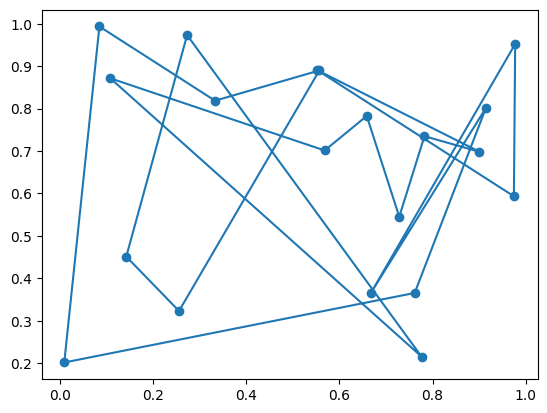

--- Tour sau khi tối ưu bằng Simulated Annealing ---
Tour length: 4.04


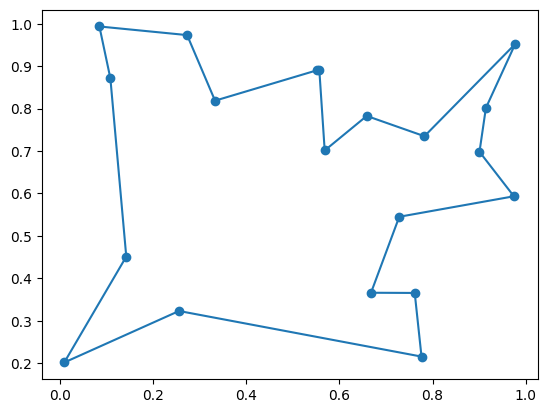

In [13]:
# Code and results go here

# Minh họa kết quả của thuật toán tốt nhất (ví dụ Simulated Annealing)
sample_tsp = random_tsp(20)
init_tour = random_tour(20)

print("--- Tour ban đầu (Ngẫu nhiên) ---")
show_tsp(sample_tsp, init_tour)


sa_res = simulated_annealing_tsp(sample_tsp)
print("--- Tour sau khi tối ưu bằng Simulated Annealing ---")
show_tsp(sample_tsp, sa_res["solution"])

## Bonus: Genetic Algorithm [+1 Point]

The algorithm continuously combines good segments from two parent paths to generate shorter new paths, while progressively eliminating poor paths over generations.

-   Randomly generate an initial population of multiple paths (e.g., 50 different tours).
-   Calculate the total distance of each path. Paths with the shortest total distance are given higher priority to be selected as "parents" for reproduction.
-   Combine a segment from Path A with a segment from Path B to generate a new Path C.
   *Note:* This combination (using the Ordered Crossover - OX technique) ensures that the new Path C visits every city without duplicates or omissions.
-   With a small probability (around 5% - 10%), a short sub-segment of the newly generated Path C is reversed (using the 2-opt operator). This introduces diversity to explore novel paths.
-   Preserve the current shortest path for the next generation (elitism) and replace the older population with the newly generated set of paths.

The algorithm terminates after repeating this crossover and selection process for a predefined number of generations (iterations).


Genetic Algorithm Best Tour Length: 2.76
Tour length: 2.76


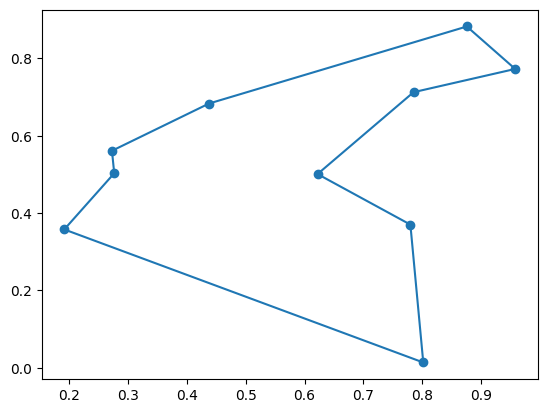

In [14]:
# Code goes here
def ordered_crossover(parent1, parent2):
    """
    Kỹ thuật lai ghépOrdered Crossover (OX) cho bài toán hoán vị TSP.
    """
    size = len(parent1)
    child = [None] * size
    
    # Chọn ngẫu nhiên 2 điểm cắt
    cxpoint1, cxpoint2 = sorted(random.sample(range(size), 2))
    
    # Sao chép đoạn con từ parent1 sang child
    child[cxpoint1:cxpoint2+1] = parent1[cxpoint1:cxpoint2+1]
    
    # Điền các phần tử còn lại từ parent2 theo đúng thứ tự
    parent2_index = 0
    for i in range(size):
        if child[i] is None:
            while parent2[parent2_index] in child:
                parent2_index += 1
            child[i] = parent2[parent2_index]
            
    return child

def mutate(tour, mutation_rate=0.05):
    """
    Đột biến bằng toán tử 2-opt ngẫu nhiên với xác suất mutation_rate.
    """
    if random.random() < mutation_rate:
        n = len(tour)
        i, j = sorted(random.sample(range(n), 2))
        tour = two_opt_swap(tour, i, j)
    return tour

def genetic_algorithm_tsp(tsp, pop_size=50, generations=500, mutation_rate=0.1, tournament_size=5):
    n = len(tsp["pos"])
    
    # 1. Khởi tạo quần thể ban đầu
    population = [random_tour(n) for _ in range(pop_size)]
    
    best_tour = None
    best_length = float('inf')
    history = []
    evaluations = 0
    
    for gen in range(generations):
        # Tính fitness cho từng cá thể
        scores = []
        for ind in population:
            length = tour_length(tsp, ind)
            evaluations += 1
            scores.append((length, ind))
            if length < best_length:
                best_length = length
                best_tour = list(ind)
                
        history.append(best_length)
        
        # 2. Tournament Selection
        def select():
            selected = random.sample(scores, tournament_size)
            selected.sort(key=lambda x: x[0])
            return selected[0][1]
        
        # 3. Tạo quần thể thế hệ mới
        new_population = [list(best_tour)]  # Elitism: Giữ lại cá thể tốt nhất
        
        while len(new_population) < pop_size:
            p1 = select()
            p2 = select()
            child = ordered_crossover(p1, p2)
            child = mutate(child, mutation_rate)
            new_population.append(child)
            
        population = new_population
        
    return {
        "solution": best_tour,
        "objective": best_length,
        "history": history,
        "iterations": generations,
        "evaluations": evaluations
    }

# Thử nghiệm chạy Genetic Algorithm
ga_res = genetic_algorithm_tsp(tsp, pop_size=50, generations=300, mutation_rate=0.1)
print(f"Genetic Algorithm Best Tour Length: {round(ga_res['objective'], 2)}")
show_tsp(tsp, ga_res["solution"])